# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import ORSSDDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 600


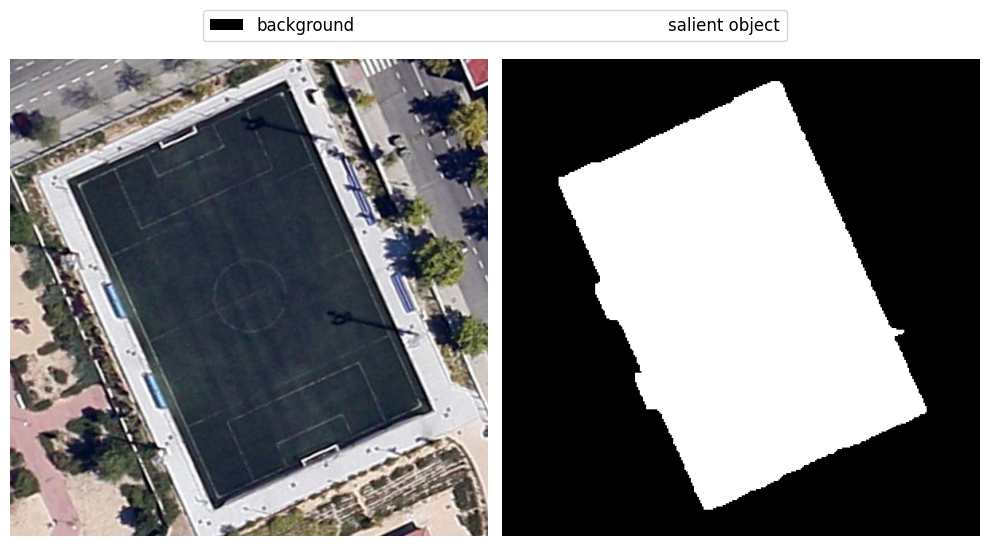

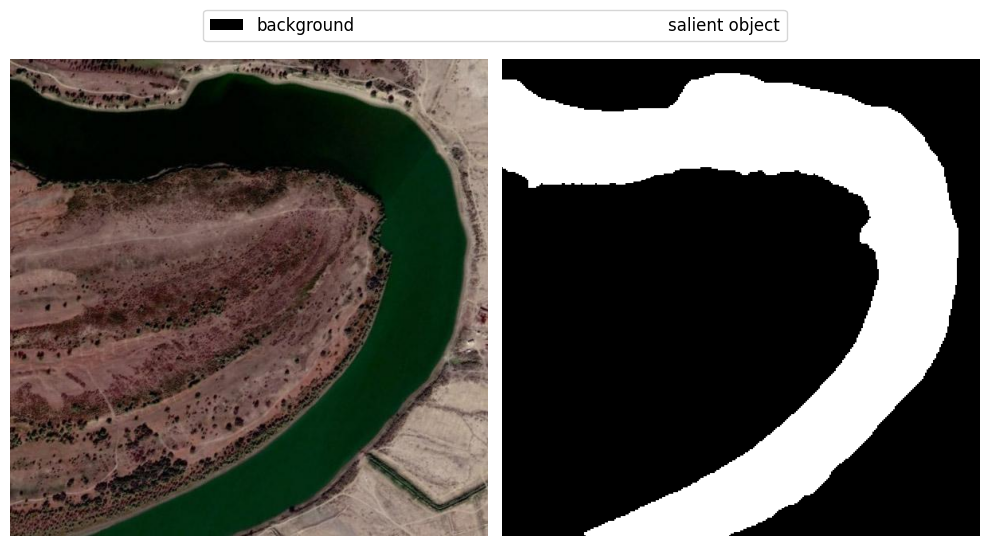

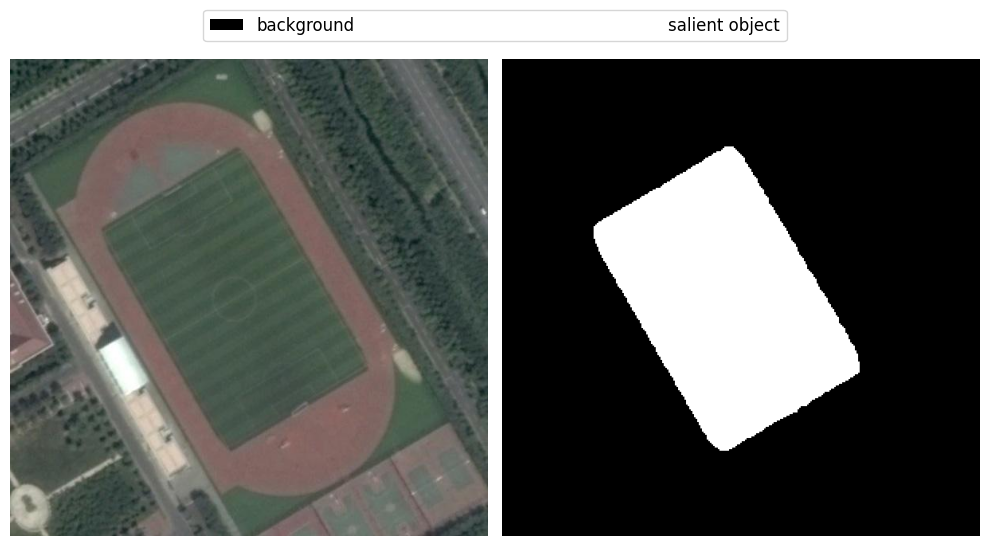

In [ ]:
dataset_config = {
    "data_dir": "./data/orssd/train"
}
dataset = ORSSDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(500);

In [10]:
dataset.data_distribution_table()

,Number of pixels
background,150003729.0
salient object,14951225.0


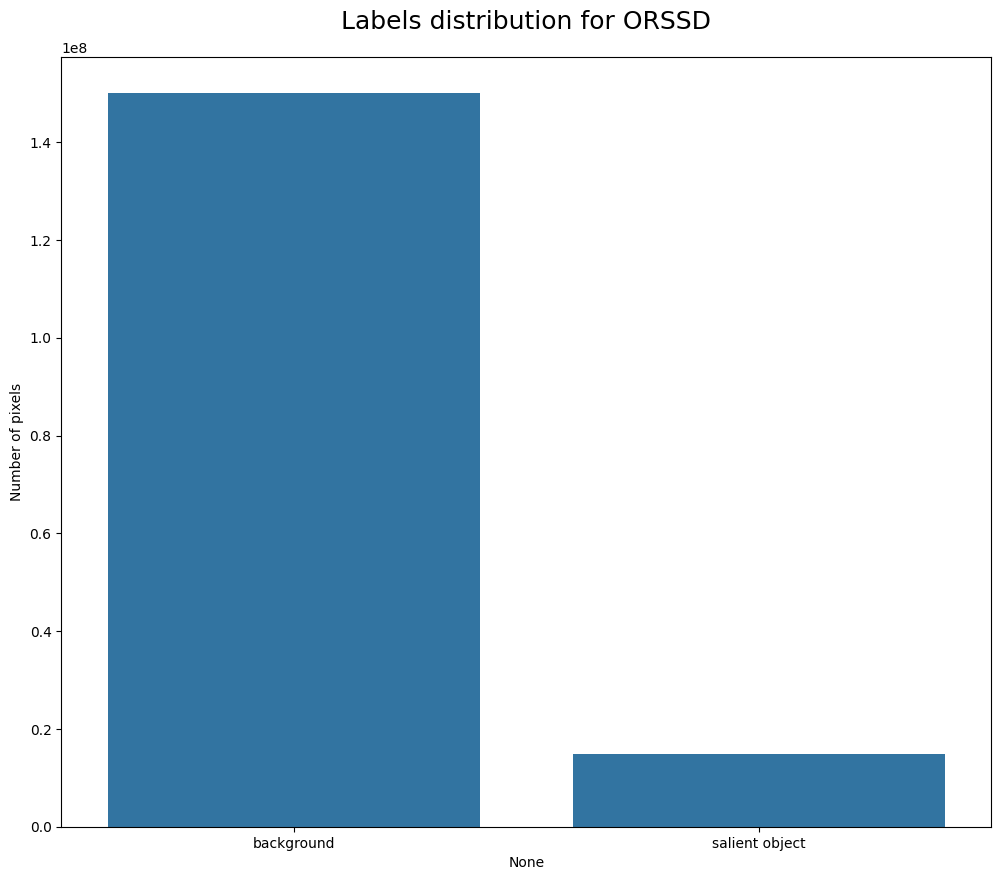

In [11]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/orssd/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = ORSSDDataset(train_dataset_config)
len(train_dataset)

600

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/orssd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [14]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-13 10:07:30,695 INFO Starting training.
training: 100%|██████████| 60/60 [02:09<00:00,  2.15s/it]
2025-11-13 10:09:40,066 INFO epoch: 1, time: 130, loss:  0.34180
testing on train set: 100%|██████████| 60/60 [02:24<00:00,  2.40s/it]
2025-11-13 10:12:05,733 INFO IOU:0.8800287074511405, IOU mean:0.7414358258257556, IOU per Class:[0.95012184 0.53274981]
training: 100%|██████████| 60/60 [02:38<00:00,  2.63s/it]
2025-11-13 10:14:43,740 INFO epoch: 2, time: 158, loss:  0.23459
testing on train set: 100%|██████████| 60/60 [02:19<00:00,  2.32s/it]
2025-11-13 10:17:02,780 INFO IOU:0.8965101720178484, IOU mean:0.757849392704646, IOU per Class:[0.96401945 0.55167933]
training: 100%|██████████| 60/60 [02:07<00:00,  2.12s/it]
2025-11-13 10:19:10,089 INFO epoch: 3, time: 128, loss:  0.18920
testing on train set: 100%|██████████| 60/60 [02:09<00:00,  2.16s/it]
2025-11-13 10:21:19,924 INFO IOU:0.9500031889050728, IOU mean:0.8626325857063222, IOU per Class:[0.97918859 0.74607658]
training: 100%

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/orssd/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ORSSDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/orssd/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

200


2025-11-13 10:52:01,156 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/orssd/checkpoint.pth.tar
2025-11-13 10:52:01,603 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/orssd/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 50/50 [00:33<00:00,  1.48it/s]


[{'IOU': 0.9587406171391283,
  'IOU mean': 0.8810723673385389,
  'IOU per Class': array([0.97777099, 0.78437374])}]

## Predictions

2025-11-13 10:52:35,334 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/orssd/checkpoint.pth.tar
2025-11-13 10:52:35,708 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/orssd/checkpoint.pth.tar at epoch 11


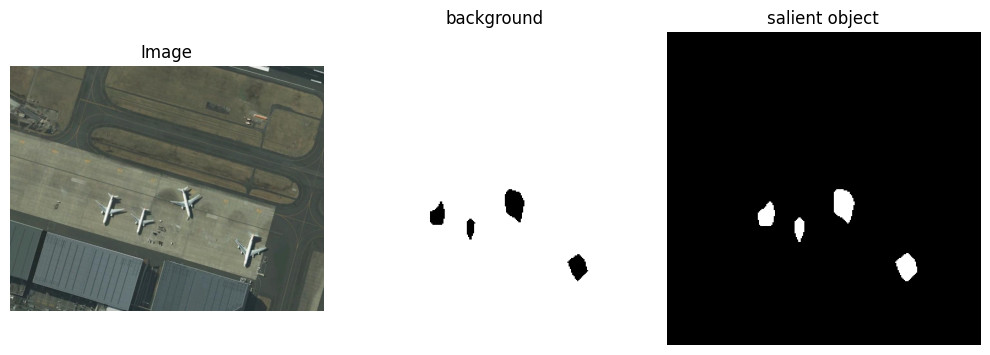

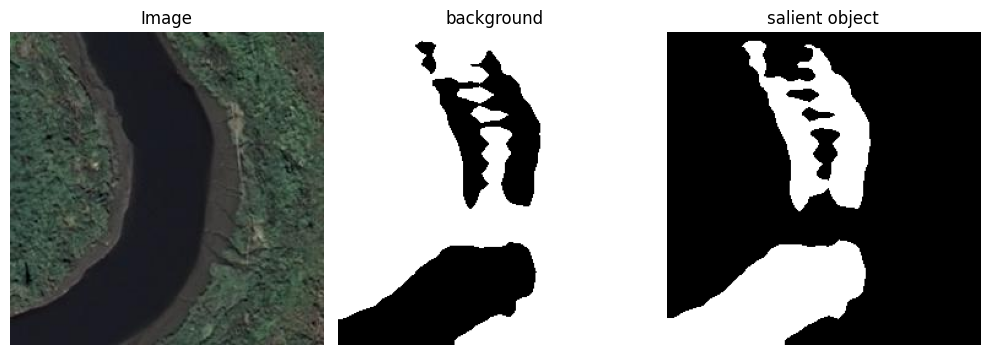

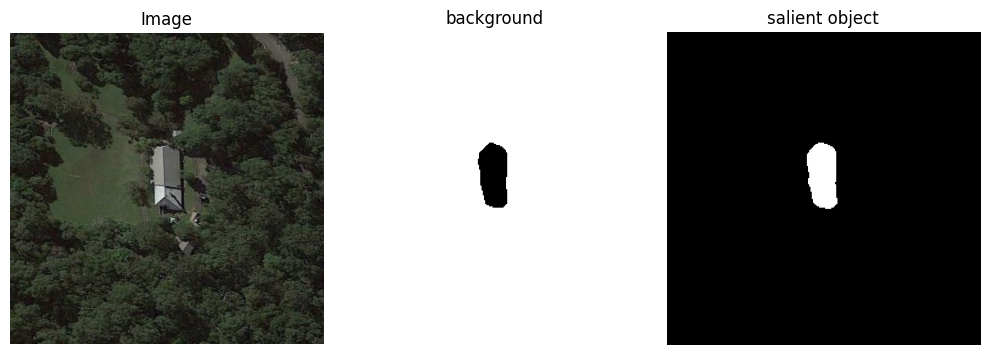

In [ ]:
model_path = "./data/experiments/orssd/checkpoint.pth.tar"
labels = ["background","salient object"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/orssd/test/images/0005.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/orssd/test/images/0250.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/orssd/test/images/0558.jpg')
fig = model.predict_masks(image, labels, transform)